<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">📘 Batch, micro-batch a streaming - Northwind </h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">V nadväznosti na Seminár 8 - Zadanie 1a s MovieLens spracujeme údaje o objednávkach. Tentoraz si jednotlivé kroky naprogramujete samostatne od načítania CSV po porovnanie výsledkov.</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z kurzu si stiahnite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> (stĺpce <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">customerid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">employeeid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid</code>). Súbor uložte do rovnakého priečinka ako notebook. Knižnice a PostgreSQL už máte pripravené.</p>

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 1 – Načítanie a časová distribúcia objednávok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Načítajte súbor <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> a zmeňte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> na dátum. Zistite časový rozsah a počet objednávok podľa roku a mesiaca. Rozloženie zobrazte v grafe.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">pd.read_csv(..., parse_dates=["orderdate"])</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.year</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.to_period("M")</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">value_counts()</code>.</div>

Počet objednávok: 196
Najstaršia objednávka: 1996-07-04 00:00:00
Najnovšia objednávka: 1997-02-12 00:00:00

Objednávky podľa roku:


orderdate
1996    152
1997     44
Name: count, dtype: int64


Objednávky podľa mesiaca (ukážka):


orderdate
1996-07    22
1996-08    25
1996-09    23
1996-10    26
1996-11    25
Freq: M, Name: count, dtype: int64

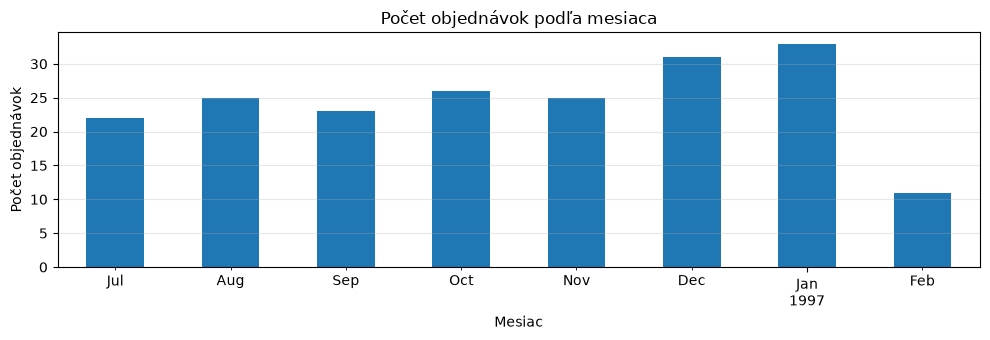

In [12]:
# Vaše riešenie
import pandas as pd
import matplotlib.pyplot as plt

orders = pd.read_csv("orders (1).csv", parse_dates=["orderdate"])

print("Počet objednávok:", len(orders))
print("Najstaršia objednávka:", orders["orderdate"].min())
print("Najnovšia objednávka:", orders["orderdate"].max())

orders_by_year = orders["orderdate"].dt.year.value_counts().sort_index()
orders_by_month = orders["orderdate"].dt.to_period("M").value_counts().sort_index()

print("\nObjednávky podľa roku:")
display(orders_by_year)

print("\nObjednávky podľa mesiaca (ukážka):")
display(orders_by_month.head())

fig, ax = plt.subplots(figsize=(10, 3.5))
orders_by_month.plot(kind="bar", ax=ax, color="tab:blue")
ax.set_title("Počet objednávok podľa mesiaca")
ax.set_xlabel("Mesiac")
ax.set_ylabel("Počet objednávok")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 2 – Historické a novšie objednávky</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Podľa časového rozloženia zvoľte <strong>hranice 1. januára 1997</strong>. Staršie objednávky budú historický batch, objednávky od tohto dátumu využijeme na simuláciu príchodu udalostí.</p>
<ul style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.7; margin-top: 6px; padding-left: 24px;"><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">historical_orders</code> budú objednávky pred hranicou,</li><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">new_orders</code> naopak objednávky od hranice (vrátane),</li><li style="margin-bottom: 5px;">overte, že obe skupiny spolu obsahujú všetky objednávky.</li></ul>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong>Upozornenie: </strong> „Novšie“ objednávky sú stále <strong>historické záznamy</strong>. V nasledujúcich úlohách budeme ich príchod len simulovať.</div>

In [ ]:
# Vaše riešenie

CUTOFF = pd.Timestamp("1997-01-01")

historical_orders = orders[orders["orderdate"] < CUTOFF].copy()
new_orders = orders[orders["orderdate"] >= CUTOFF].copy()

print("Historické objednávky:", len(historical_orders))
print("Novšie objednávky:", len(new_orders))


assert len(historical_orders) + len(new_orders) == len(orders)
assert set(historical_orders["orderid"]).isdisjoint(set(new_orders["orderid"]))



Historické objednávky: 152
Novšie objednávky: 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 3 – Raw ingestion do PostgreSQL</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte databázu <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">Northwind</code>, tabuľku <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> s primárnym kľúčom <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code> a nahrajte všetky záznamy z CSV. Predpokladáme, že PostgreSQL a balíky už fungujú inštaláciu ani test verzie preto nemusíte riešiť.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> najskôr sa pripojte do databázy <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">postgres</code>, vytvorte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders_practice</code> s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">AUTOCOMMIT</code>, potom zmeňte pripojenie. Na opakovateľný import použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">DROP TABLE IF EXISTS</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">to_sql(..., if_exists="append", index=False)</code>.</div>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong> Upozornenie:</strong> Pri opakovanom spustení sa obsah tabuľky <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> vymaže a znovu nahrá. Nepoužívajte názov databázy, ktorá už obsahuje vaše vlastné dáta.</div>

In [14]:
pip install "psycopg[binary]"

Note: you may need to restart the kernel to use updated packages.


In [16]:
import pandas as pd
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

DB_USER = "postgres"
DB_PASSWORD = "Student"  
DB_HOST = "127.0.0.1"     
DB_PORT = 5432
DB_NAME = "northwind"


def make_engine(database, **kwargs):

    url = URL.create(
        "postgresql+psycopg",
        username=DB_USER,
        password=DB_PASSWORD,
        host=DB_HOST,
        port=DB_PORT,
        database=database,
    )
    return create_engine(url, **kwargs)



admin_engine = make_engine("postgres", isolation_level="AUTOCOMMIT")
with admin_engine.connect() as conn:
    exists = conn.execute(
        text("SELECT 1 FROM pg_database WHERE datname = :name"), {"name": DB_NAME}
    ).scalar()
    if not exists:
        conn.execute(text(f"CREATE DATABASE {DB_NAME}"))
admin_engine.dispose()

engine = make_engine(DB_NAME)


def sql_type(series):

    return "INTEGER" if pd.api.types.is_integer_dtype(series) else "VARCHAR(20)"

with engine.begin() as conn:
    conn.execute(text("DROP TABLE IF EXISTS orders"))
    conn.execute(text(f"""
        CREATE TABLE orders (
            orderid     INTEGER PRIMARY KEY,
            customerid  {sql_type(orders["customerid"])},
            employeeid  INTEGER,
            orderdate   DATE,
            shipperid   INTEGER
        )
    """))

orders.to_sql("orders", engine, if_exists="append", index=False, chunksize=5000)

with engine.connect() as conn:
    n_rows = conn.execute(text("SELECT COUNT(*) FROM orders")).scalar()

assert n_rows == len(orders)
print("Tabuľka orders bola vytvorená a naplnená.")

Tabuľka orders bola vytvorená a naplnená.


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 4 – Batch processing</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z historických objednávok vypočítajte <strong>počet objednávok</strong>, <strong>počet zákazníkov</strong> a <strong>percento objednávok s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid = 3</code></strong>. Výsledok získame jednorazovo za celú historickú skupinu.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Percento vypočítate ako <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(počet objednávok dopravcu 3 / počet všetkých objednávok) * 100</code>. Výraz <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(df["shipperid"] == 3).sum()</code> spočíta vyhovujúce riadky.</div>

In [18]:
# # Vaše riešenie
total_orders = len(orders)
total_customers = orders["customerid"].nunique()
shipper_3_percent = (
    (orders["shipperid"] == 3).sum() / total_orders
) * 100

print(f"Objednávok: {total_orders}")
print(f"Zákazníkov: {total_customers}")
print(f"Dopravca 3 (%): {shipper_3_percent:.2f}")


Objednávok: 196
Zákazníkov: 74
Dopravca 3 (%): 34.69


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 5 – Spoločná vzorka pre tri prístupy</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na porovnanie musí každý prístup dostať <strong>rovnaké objednávky v rovnakom poradí</strong>. Z PostgreSQL vyberte novšie objednávky a zoraďte ich podľa <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">text()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">engine.connect()</code> a pomenované parametre SQL <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:cutoff</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:limit</code>. V tomto datasete je po hranici 44 objednávok, preto postačuje <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">SAMPLE_SIZE = 44</code>.</div>

In [19]:
# Vaše riešenie
SAMPLE_SIZE = 44
CUTOFF_DATE = "1996-01-01"  

query = text("""
    SELECT * 
    FROM orders 
    WHERE orderdate >= :cutoff
    ORDER BY orderdate DESC, orderid DESC
    LIMIT :limit
""")

with engine.connect() as conn:
    df_sample = pd.read_sql(query, conn, params={"cutoff": CUTOFF_DATE, "limit": SAMPLE_SIZE})

df_sample = df_sample.sort_values(by=["orderdate", "orderid"]).reset_index(drop=True)

print(f"Objednávok v simulácii: {len(df_sample)}")

Objednávok v simulácii: 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 6 – Simulácia micro-batchingu a streamingu</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Historické objednávky budeme prehrávať postupne. <strong>Streaming</strong> aktualizuje podiel dopravcu 3 po každej objednávke, <strong>micro-batch</strong> po uzavretí krátkeho časového okna. Batch poskytne výsledok až po príchode celej vzorky.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Pre tento malý dataset nastavíme <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">EVENT_DELAY_SEC = 0.04</code> (40 ms medzi objednávkami) a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">MICRO_WINDOW_SEC = 0.30</code> (približne 300 ms na dávku). Skutočné časy závisia od výkonu počítača.</div>

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok A – Nastavenia a priebežný stav</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Pripravte časové parametre, počítadlá a zoznamy na zaznamenávanie priebežných výsledkov. Pri micro-batchingu potrebujeme navyše premenné pre neuzavretú dávku.</p>

In [20]:
# Vaše riešenie
import time
from datetime import datetime

EVENT_DELAY_SEC = 0.04
MICRO_WINDOW_SEC = 0.30

stream_results = []     
micro_batch_results = [] 

total_count = 0
shipper_3_count = 0

current_batch_orders = []
batch_start_time = time.time()

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok B – Spracovanie udalostí</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Prejdite objednávky postupne. Pri streamingu priebežne zapisujte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(čas, počet, percento)</code>. Pri micro-batchingu spracujte nazbierané objednávky až po uplynutí okna.</p>

In [21]:
for _, row in df_sample.iterrows():
    event_time = time.time()
    
    total_count += 1
    if row["shipperid"] == 3:
        shipper_3_count += 1
    
    current_pct = (shipper_3_count / total_count) * 100
    stream_results.append((event_time, total_count, current_pct))
    
    current_batch_orders.append(row)
    
    if (event_time - batch_start_time) >= MICRO_WINDOW_SEC:
        if current_batch_orders:
            b_total = len(current_batch_orders)
            b_sh3 = sum(1 for r in current_batch_orders if r["shipperid"] == 3)
            b_pct = (b_sh3 / b_total) * 100 if b_total > 0 else 0
            micro_batch_results.append((event_time, b_total, b_pct))
            current_batch_orders = []
        batch_start_time = time.time()
  
    time.sleep(EVENT_DELAY_SEC)


<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok C – Posledná dávka a batch</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Nezabudnite spracovať poslednú nedokončenú micro-batch dávku. Nakoniec vypočítajte jednorazový batch výsledok pre tú istú vzorku a overte rovnosť výsledných percent.</p>

In [ ]:

if current_batch_orders:
    b_total = len(current_batch_orders)
    b_sh3 = sum(1 for r in current_batch_orders if r["shipperid"] == 3)
    b_pct = (b_sh3 / b_total) * 100 if b_total > 0 else 0
    micro_batch_results.append((time.time(), b_total, b_pct))

batch_total = len(df_sample)
batch_sh3 = (df_sample["shipperid"] == 3).sum()
batch_pct = (batch_sh3 / batch_total) * 100

final_stream_pct = stream_ict = stream_results[-1][2] if stream_results else 0
final_mb_pct = micro_batch_results[-1][2] if micro_batch_results else 0

print(f"Počet objednávok: {batch_total}")
print(f"Batch (%): {batch_pct:.2f}")
print(f"Micro-batch (%): {final_mb_pct:.2f}")
print(f"Streaming (%): {final_stream_pct:.2f}")



Počet objednávok: 44
Batch (%): 22.73
Micro-batch (%): 0.00
Streaming (%): 22.73


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 7 – Grafy priebežných výsledkov</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte <strong>tri samostatné grafy</strong> pod sebou. V prvom zobrazte jednorazový batch bod, v druhom schodovitý priebeh micro-batchingu a v treťom streamingovú krivku. Použite spoločné osi, aby boli percentá porovnateľné.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plt.subplots(3, 1, sharex=True, sharey=True)</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">scatter()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">step(where="post")</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plot()</code>.</div>

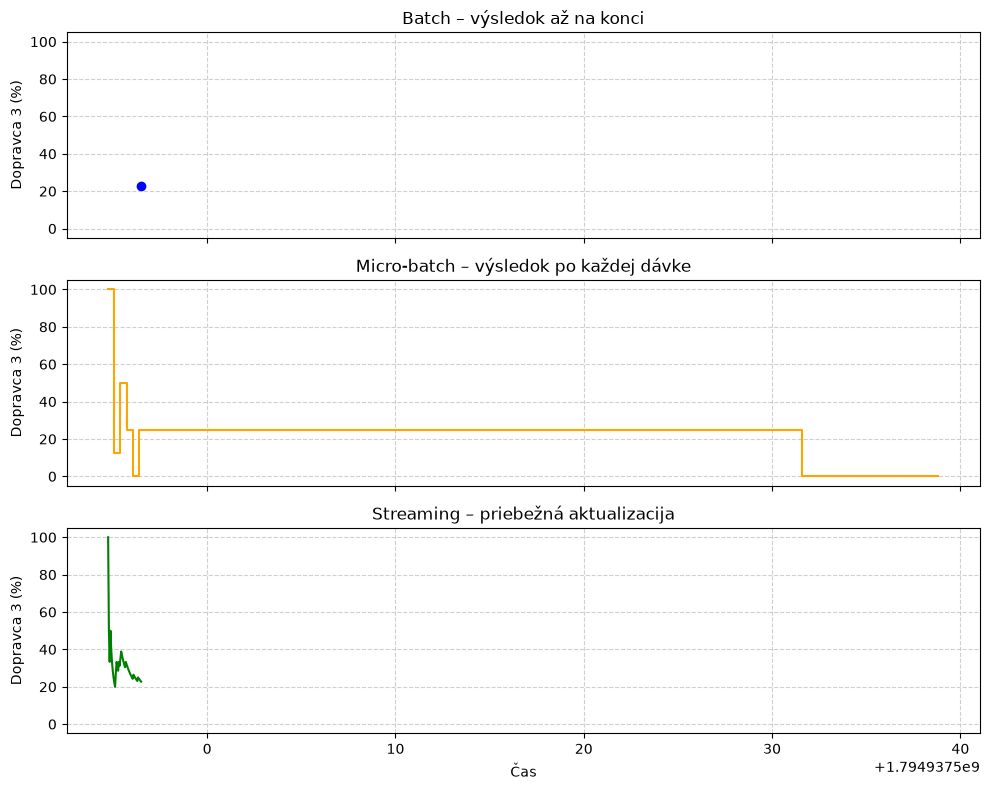

In [26]:
# Vaše riešenie
import matplotlib.pyplot as plt

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, sharey=True, figsize=(10, 8))


batch_time = stream_results[-1][0] if stream_results else 0
ax1.scatter([batch_time], [batch_pct], color="blue", label="Batch")
ax1.set_title("Batch – výsledok až na konci")
ax1.set_ylabel("Dopravca 3 (%)")
ax1.grid(True, linestyle="--", alpha=0.6)

mb_times = [res[0] for res in micro_batch_results]
mb_pcts = [res[2] for res in micro_batch_results]
if mb_times:
    ax2.step(mb_times, mb_pcts, where="post", color="orange", label="Micro-batch")
ax2.set_title("Micro-batch – výsledok po každej dávke")
ax2.set_ylabel("Dopravca 3 (%)")
ax2.grid(True, linestyle="--", alpha=0.6)

stream_times = [res[0] for res in stream_results]
stream_pcts = [res[2] for res in stream_results]
if stream_times:
    ax3.plot(stream_times, stream_pcts, color="green", label="Streaming")
ax3.set_title("Streaming – priebežná aktualizacija")
ax3.set_xlabel("Čas")
ax3.set_ylabel("Dopravca 3 (%)")
ax3.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 8 – Frekvencia aktualizácií a prvý výsledok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na troch grafoch znázornite, koľkokrát sa priebežný výsledok aktualizoval. Potom vytvorte jednoduchú tabuľku, ktorá porovná <strong>čas prvého výsledku</strong>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Pri počte aktualizácií nie je vhodné zdieľať os Y: batch má jeden výsledok, streaming jeden po každej udalosti. Os X zdieľajte.</div>

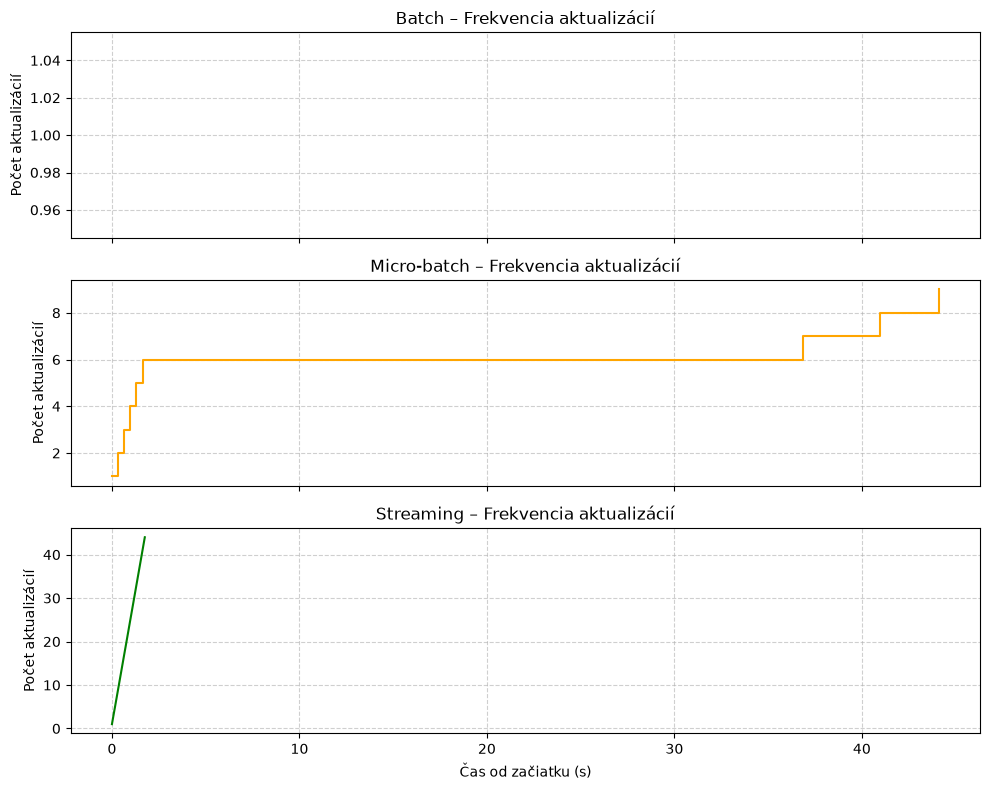

,Prístup,Počet aktualizácií celkovo,Čas prvého výsledku (s)
0,Batch,1,1.752
1,Micro-batch,9,0.000
2,Streaming,44,0.000


In [28]:
# Vaše riešenie
import pandas as pd
import matplotlib.pyplot as plt

start_time = stream_results[0][0] if stream_results else 0

batch_x = [batch_time - start_time]
batch_y = [1]

mb_x = [res[0] - start_time for res in micro_batch_results]
mb_y = list(range(1, len(mb_x) + 1))

stream_x = [res[0] - start_time for res in stream_results]
stream_y = list(range(1, len(stream_x) + 1))

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(10, 8))

ax1.step(batch_x, batch_y, where="post", color="blue", label="Batch")
ax1.set_title("Batch – Frekvencia aktualizácií")
ax1.set_ylabel("Počet aktualizácií")
ax1.grid(True, linestyle="--", alpha=0.6)

ax2.step(mb_x, mb_y, where="post", color="orange", label="Micro-batch")
ax2.set_title("Micro-batch – Frekvencia aktualizácií")
ax2.set_ylabel("Počet aktualizácií")
ax2.grid(True, linestyle="--", alpha=0.6)

ax3.plot(stream_x, stream_y, color="green", label="Streaming")
ax3.set_title("Streaming – Frekvencia aktualizácií")
ax3.set_xlabel("Čas od začiatku (s)")
ax3.set_ylabel("Počet aktualizácií")
ax3.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

first_batch_time = (batch_time - start_time) if batch_x else 0
first_mb_time = (micro_batch_results[0][0] - start_time) if micro_batch_results else 0
first_stream_time = (stream_results[0][0] - start_time) if stream_results else 0

comparison_data = {
    "Prístup": ["Batch", "Micro-batch", "Streaming"],
    "Počet aktualizácií celkovo": [len(batch_x), len(mb_x), len(stream_x)],
    "Čas prvého výsledku (s)": [round(first_batch_time, 3), round(first_mb_time, 3), round(first_stream_time, 3)]
}

df_comparison = pd.DataFrame(comparison_data)
display(df_comparison)

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">
  📘 Kontrola Git repozitára po 8. týždni
</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Po dokončení všetkých úloh z 8. týždňa skontrolujte, či máte vo svojom Git
  repozitári vytvorenú samostatnú vetvu
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  a či sa v nej nachádza vypracovaný notebook vytvorený počas cvičenia.
</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Obsah vetvy
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  by mal mať približne nasledujúcu štruktúru:
</p>
<pre style="background: #f9fafb; color: #111827; padding: 14px; border-radius: 7px; overflow: auto; font-size: 13px; line-height: 1.7; font-family: ui-monospace, SFMono-Regular, Menlo, monospace;">week-08
│
├── ratings.csv
├── orders.csv
│
├── batch_streaming.ipynb
└── batch_streaming_orders.ipynb
</pre>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #eab308; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">
  ⚠️ <strong>Kontrola GitHubu:</strong> Skontrolujte, či sa všetky uvedené súbory
  nachádzajú aj vo vzdialenom repozitári na GitHube. Ak ich vidíte iba lokálne
  vo VS Code, zmeny ešte neboli úspešne odoslané pomocou
  <strong>commit</strong> a <strong>push</strong>.
</div>